In [ ]:
# ==========================================
# SETUP
# ==========================================

In [2]:
# ==========================================
# 1. Imports & Device Configuration
# ==========================================
import torch
import torch.nn as nn
import torchvision.models as models
import numpy as np

# Set device to GPU if available, else CPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

# Number of classes in our HAM10000 dataset
NUM_CLASSES = 7

print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available (GPU) : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"Graphics card : {torch.cuda.get_device_name(0)}")

Using device: cuda
PyTorch version: 2.7.1+cu118
CUDA available (GPU) : True
Graphics card : NVIDIA GeForce GTX 1650


In [3]:
# ==========================================
# 1.5. RE-CREATING DATA LOADERS
# ==========================================
import pandas as pd
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path

# 1. Load Paths and Dataframe
BASE_DIR = Path('..')
DATA_DIR = BASE_DIR / 'data'
IMAGE_DIR = DATA_DIR / 'all_images'
METADATA_PATH = DATA_DIR / 'HAM10000_metadata.csv'

df = pd.read_csv(METADATA_PATH)
df['path'] = df['image_id'].apply(lambda x: IMAGE_DIR / f"{x}.jpg")

# 2. Re-define Dataset Class and Transforms
class SkinCancerDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df
        self.transform = transform
        self.label_map = {'nv': 0, 'mel': 1, 'bkl': 2, 'bcc': 3, 'akiec': 4, 'vasc': 5, 'df': 6}

    def __len__(self): return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]['path']
        label_str = self.df.iloc[idx]['dx']
        image = Image.open(img_path).convert('RGB')
        if self.transform: image = self.transform(image)
        import torch # Ensure torch is available here
        return image, torch.tensor(self.label_map[label_str], dtype=torch.long)

NORM_MEAN, NORM_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
train_transforms = transforms.Compose([
    transforms.Resize((224, 224)), transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5), transforms.RandomRotation(20),
    transforms.ToTensor(), transforms.Normalize(NORM_MEAN, NORM_STD)
])
val_transforms = transforms.Compose([
    transforms.Resize((224, 224)), transforms.ToTensor(), transforms.Normalize(NORM_MEAN, NORM_STD)
])

# 3. Stratified Split and DataLoaders creation
train_df, val_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['dx'])

train_dataset = SkinCancerDataset(train_df, transform=train_transforms)
val_dataset = SkinCancerDataset(val_df, transform=val_transforms)

BATCH_SIZE = 32
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"DataLoaders successfully loaded! Train batches: {len(train_loader)}, Val batches: {len(val_loader)}")

DataLoaders successfully loaded! Train batches: 251, Val batches: 63


In [4]:
# ==========================================
# 2. Building the Transfer Learning Model
# ==========================================

def create_resnet34_model(num_classes, freeze_base=True):
    """
    Loads a pre-trained ResNet34 and modifies its final layer.
    """
    # 1. Load the pre-trained model (using modern PyTorch weights API)
    weights = models.ResNet34_Weights.IMAGENET1K_V1
    model = models.resnet34(weights=weights)
    
    # 2. Freeze the base layers (Feature Extractor)
    if freeze_base:
        for param in model.parameters():
            param.requires_grad = False
            
    # 3. Replace the classification head
    # ResNet's final fully connected layer is called 'fc'
    # We get the number of input features going into that layer
    num_ftrs = model.fc.in_features
    
    # We replace it with a new Linear layer outputting our 7 classes
    # By default, new layers have requires_grad=True, so this part WILL train
    model.fc = nn.Linear(num_ftrs, num_classes)
    
    return model

# Instantiate the model and move it to the GPU
model = create_resnet34_model(NUM_CLASSES, freeze_base=True)
model = model.to(device)

print("Model architecture ready and moved to GPU.")

Model architecture ready and moved to GPU.


In [5]:
# ==========================================
# 3. Loss Function (Handling Imbalance) & Optimizer
# ==========================================

# Example distribution from our EDA (approximate counts)
# 0: nv (6705), 1: mel (1113), 2: bkl (1099), 3: bcc (514), 4: akiec (327), 5: vasc (142), 6: df (115)
class_counts = np.array([6705, 1113, 1099, 514, 327, 142, 115])

# Calculate weights: Inverse of frequency
# The less frequent a class is, the higher its weight
weights = 1.0 / class_counts

# Normalize weights so they aren't massive numbers (optional but good practice)
weights = weights / weights.sum()

# Convert to PyTorch tensor and move to GPU
class_weights_tensor = torch.tensor(weights, dtype=torch.float).to(device)

# Define the Loss function with the weights
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# Define the Optimizer
# We ONLY pass the parameters that require gradients (our new 'fc' layer)
# Adam is a standard, very efficient optimizer
optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=0.001)

print("Criterion (Loss) and Optimizer configured successfully.")

Criterion (Loss) and Optimizer configured successfully.


In [ ]:
# ==========================================
# TRAINING
# ==========================================

In [6]:
# ==========================================
# 1. Training Loop Definition
# ==========================================
import time
import copy
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

def train_model(model, criterion, optimizer, train_loader, val_loader, device, num_epochs=5):
    """
    Trains the ResNet model and evaluates it using medical-grade metrics.
    """
    since = time.time()
    
    # Keep track of the best model weights to save them later
    best_model_wts = copy.deepcopy(model.state_dict())
    best_loss = float('inf')
    
    # Dictionaries to keep track of loss history for plotting
    history = {'train_loss': [], 'val_loss': []}

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        # Each epoch has a training and validation phase
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()  # Set model to training mode (enables dropout, updates weights)
                dataloader = train_loader
            else:
                model.eval()   # Set model to evaluate mode (freezes weights)
                dataloader = val_loader

            running_loss = 0.0
            
            # Lists to store true labels and predictions for sklearn metrics
            all_preds = []
            all_labels = []

            # Iterate over data
            for inputs, labels in dataloader:
                inputs = inputs.to(device)
                labels = labels.to(device)

                # Zero the parameter gradients
                optimizer.zero_grad()

                # Forward pass
                # Track history only if in training phase
                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    # Backward pass + optimize only if in training phase
                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                # Statistics
                running_loss += loss.item() * inputs.size(0)
                
                # Store predictions and labels for metrics calculation
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

            # Calculate average loss for the epoch
            epoch_loss = running_loss / len(dataloader.dataset)
            history[f'{phase}_loss'].append(epoch_loss)

            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f}')

            # Deep copy the model if it's the best validation loss we've seen
            if phase == 'val' and epoch_loss < best_loss:
                best_loss = epoch_loss
                best_model_wts = copy.deepcopy(model.state_dict())
                
            # Print detailed metrics at the end of Validation phase
            if phase == 'val':
                print("\n--- Validation Metrics ---")
                # target_names assumes the order from our label_map: 0:nv, 1:mel, 2:bkl, etc.
                target_names = ['nv', 'mel', 'bkl', 'bcc', 'akiec', 'vasc', 'df']
                print(classification_report(all_labels, all_preds, target_names=target_names, zero_division=0))
                
                # We return the last epoch's labels and preds to plot the confusion matrix
                last_val_labels = all_labels
                last_val_preds = all_preds

    time_elapsed = time.time() - since
    print(f'\nTraining complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best Validation Loss: {best_loss:.4f}')

    # Load best model weights
    model.load_state_dict(best_model_wts)
    return model, history, last_val_labels, last_val_preds

In [7]:
# ==========================================
# 2. Execution of the Training Loop
# ==========================================

# Run the training! (This might take 5-15 minutes depending on your batch size and GPU)
print("Starting training...")
best_model, training_history, val_labels, val_preds = train_model(
    model=model,
    criterion=criterion,
    optimizer=optimizer,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    num_epochs=5
)

# Save the trained model weights to your 'models' folder
# This is crucial so you don't have to retrain every time!
import os
os.makedirs('../models', exist_ok=True)
torch.save(best_model.state_dict(), '../models/resnet34_derma_v1.pth')
print("\nModel saved successfully to '../models/resnet34_derma_v1.pth'")

Starting training...

Epoch 1/5
----------
Train Loss: 1.5918
Val Loss: 1.3509

--- Validation Metrics ---
              precision    recall  f1-score   support

          nv       0.96      0.60      0.74      1341
         mel       0.26      0.62      0.36       223
         bkl       0.38      0.68      0.49       220
         bcc       0.41      0.43      0.42       103
       akiec       0.38      0.17      0.23        65
        vasc       0.23      0.57      0.33        28
          df       0.24      0.35      0.29        23

    accuracy                           0.59      2003
   macro avg       0.41      0.49      0.41      2003
weighted avg       0.76      0.59      0.63      2003


Epoch 2/5
----------
Train Loss: 1.2583
Val Loss: 1.2863

--- Validation Metrics ---
              precision    recall  f1-score   support

          nv       0.97      0.56      0.71      1341
         mel       0.31      0.35      0.33       223
         bkl       0.37      0.70      0.49    

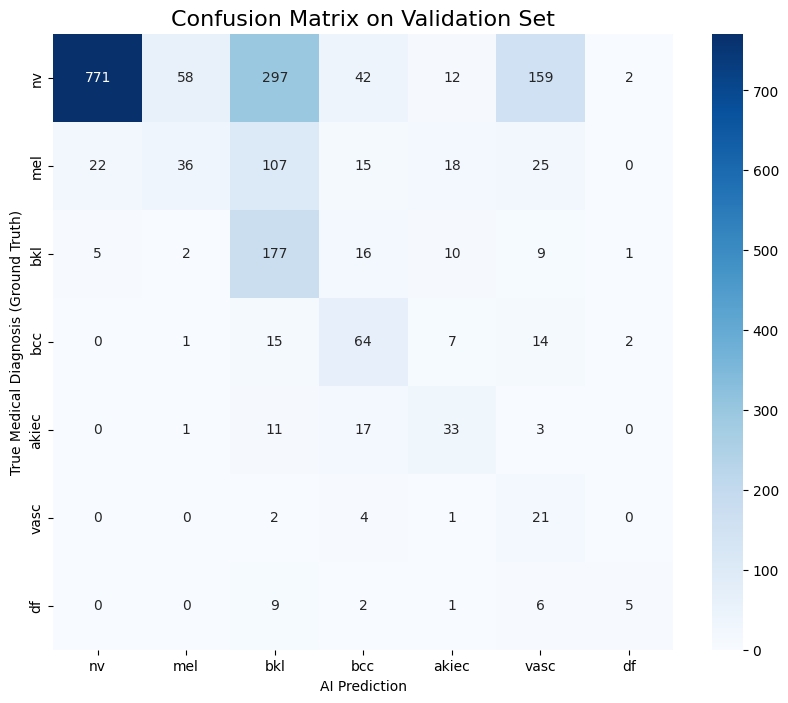


=== CRITICAL MEDICAL REPORT: MELANOMA (mel) ===
Total actual Melanomas in Validation Set: 223
✅ True Positives (Successfully detected): 36
❌ FALSE NEGATIVES (MISSED CANCERS - DANGER): 187 (83.9%)
⚠️ False Positives (False alarms): 62
We prioritize minimizing False Negatives. A False Positive just means a biopsy is done as a precaution. A False Negative means sending a sick patient home.


In [8]:
# ==========================================
# 3. Medical Evaluation: Confusion Matrix & False Negatives
# ==========================================

# Recreate the target names list
target_names = ['nv', 'mel', 'bkl', 'bcc', 'akiec', 'vasc', 'df']

# Generate the confusion matrix
cm = confusion_matrix(val_labels, val_preds)

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.title('Confusion Matrix on Validation Set', fontsize=16)
plt.ylabel('True Medical Diagnosis (Ground Truth)')
plt.xlabel('AI Prediction')
plt.show()

# --- Deep Dive into Melanoma (mel) ---
# In our mapping, 'mel' is index 1.
mel_index = 1

# True Positives: The AI correctly identified a Melanoma
tp_mel = cm[mel_index, mel_index]

# False Negatives (THE MOST CRITICAL METRIC): 
# It WAS a Melanoma, but the AI predicted something else.
# We sum the row for 'mel', excluding the correct prediction.
fn_mel = sum(cm[mel_index, :]) - tp_mel

# False Positives: It was NOT a Melanoma, but the AI panicked and said it was.
# We sum the column for 'mel', excluding the correct prediction.
fp_mel = sum(cm[:, mel_index]) - tp_mel

total_mel_in_val = tp_mel + fn_mel

print("\n=== CRITICAL MEDICAL REPORT: MELANOMA (mel) ===")
print(f"Total actual Melanomas in Validation Set: {total_mel_in_val}")
print(f"✅ True Positives (Successfully detected): {tp_mel}")
print(f"❌ FALSE NEGATIVES (MISSED CANCERS - DANGER): {fn_mel} ({(fn_mel/total_mel_in_val)*100:.1f}%)")
print(f"⚠️ False Positives (False alarms): {fp_mel}")

print("We prioritize minimizing False Negatives. A False Positive just means a biopsy is done as a precaution. A False Negative means sending a sick patient home.")

In [ ]:
# ==========================================
# SECOND TRAINING
# ==========================================

In [7]:
# ==========================================
# 1. Fine-Tuning Setup: Unfreezing and Optimizer
# ==========================================
import torch
import torch.nn as nn
from torch.optim import lr_scheduler

# Assuming 'model' is already in memory from the previous step. Uncomment if notebook was restarted.
model = create_resnet34_model(NUM_CLASSES, freeze_base=True)
model.load_state_dict(torch.load('../models/resnet34_derma_v1.pth'))
model = model.to(device)

print("Configuring model for Fine-Tuning...")

# 1. Unfreeze the last convolutional block of ResNet34 (layer4)
# We keep layer1, layer2, and layer3 frozen to retain basic image features
for param in model.layer4.parameters():
    param.requires_grad = True

# 2. Verify which layers are currently trainable
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Number of trainable parameters: {trainable_params:,}")

# 3. Setup Optimizer with Differential Learning Rates
# - layer4 gets a very small learning rate (1e-4) to carefully tune its weights
# - fc (the classification head) gets a slightly larger one (1e-3)
optimizer_ft = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4},
    {'params': model.fc.parameters(), 'lr': 1e-3}
])

# 4. Setup Learning Rate Scheduler
# ReduceLROnPlateau drops the learning rate when a metric has stopped improving.
# 'min' means we want to minimize the validation loss.
# 'patience=3' means we wait for 3 epochs of no improvement before dropping the LR by 'factor=0.1'
scheduler = lr_scheduler.ReduceLROnPlateau(optimizer_ft, mode='min', factor=0.1, patience=3)

# 5. Keep the same weighted loss function as before
# criterion = nn.CrossEntropyLoss(weight=class_weights_tensor) # Already defined previously

print("Optimizer and Scheduler ready.")

Configuring model for Fine-Tuning...
Number of trainable parameters: 13,117,959
Optimizer and Scheduler ready.


In [8]:
# ==========================================
# 2. Advanced Training Loop (with Scheduler & Early Stopping)
# ==========================================
import time
import copy
from sklearn.metrics import classification_report, confusion_matrix

def train_model_advanced(model, criterion, optimizer, scheduler, train_loader, val_loader, device, num_epochs=20, early_stopping_patience=6):
    """
    Trains the model with Learning Rate Scheduling and Early Stopping.
    """
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_loss = float('inf')
    
    epochs_no_improve = 0 # Counter for Early Stopping

    for epoch in range(num_epochs):
        print(f'\nEpoch {epoch+1}/{num_epochs}')
        print('-' * 10)

        # Log for current Learning Rate (layer4)
        current_lr = optimizer.param_groups[0]['lr']
        print(f'Current Learning Rate: {current_lr}')
        
        for phase in ['train', 'val']:
            if phase == 'train':
                model.train()
                dataloader = train_loader
            else:
                model.eval()
                dataloader = val_loader

            running_loss = 0.0
            all_preds = []
            all_labels = []

            for inputs, labels in dataloader:
                inputs, labels = inputs.to(device), labels.to(device)
                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == 'train'):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == 'train':
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())

            epoch_loss = running_loss / len(dataloader.dataset)
            print(f'{phase.capitalize()} Loss: {epoch_loss:.4f}')

            # --- VALIDATION PHASE LOGIC ---
            if phase == 'val':
                # 1. Step the scheduler based on validation loss
                scheduler.step(epoch_loss)
                
                # 2. Check for improvement (Early Stopping logic)
                if epoch_loss < best_loss:
                    best_loss = epoch_loss
                    best_model_wts = copy.deepcopy(model.state_dict())
                    epochs_no_improve = 0 # Reset counter
                    print(f"🌟 New best model found! Loss: {best_loss:.4f}")
                    
                    # Store best predictions for the final report
                    best_val_labels = all_labels
                    best_val_preds = all_preds
                else:
                    epochs_no_improve += 1
                    print(f"Early stopping counter: {epochs_no_improve} out of {early_stopping_patience}")

        # Break out of the epochs loop if we haven't improved in a while
        if epochs_no_improve >= early_stopping_patience:
            print("\n🛑 Early stopping triggered! The model stopped improving.")
            break

    time_elapsed = time.time() - since
    print(f'\nTraining complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s')
    print(f'Best Validation Loss: {best_loss:.4f}')

    # Load best model weights
    model.load_state_dict(best_model_wts)
    return model, best_val_labels, best_val_preds

In [9]:
# ==========================================
# 3. Execution of Fine-Tuning
# ==========================================

print("Starting Fine-Tuning...")
fine_tuned_model, val_labels, val_preds = train_model_advanced(
    model=model,
    criterion=criterion,
    optimizer=optimizer_ft,
    scheduler=scheduler,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    num_epochs=20, # Increased epochs
    early_stopping_patience=6
)

# Save the newly fine-tuned model
torch.save(fine_tuned_model.state_dict(), '../models/resnet34_derma_finetuned_v2.pth')
print("\nFine-tuned model saved to '../models/resnet34_derma_finetuned_v2.pth'")

# ==========================================
# 4. Final Evaluation of the Fine-Tuned Model
# ==========================================
target_names = ['nv', 'mel', 'bkl', 'bcc', 'akiec', 'vasc', 'df']

print("\n=== FINE-TUNED VALIDATION METRICS ===")
print(classification_report(val_labels, val_preds, target_names=target_names, zero_division=0))

cm = confusion_matrix(val_labels, val_preds)
mel_index = 1
tp_mel = cm[mel_index, mel_index]
fn_mel = sum(cm[mel_index, :]) - tp_mel

print("\n=== CRITICAL MEDICAL REPORT: MELANOMA (mel) AFTER FINE-TUNING ===")
print(f"✅ True Positives: {tp_mel}")
print(f"❌ FALSE NEGATIVES: {fn_mel} (Hopefully much lower than 187!)")

Starting Fine-Tuning...

Epoch 1/20
----------
Current Learning Rate: 0.0001
Train Loss: 1.1044
Val Loss: 0.9668
🌟 New best model found! Loss: 0.9668

Epoch 2/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.7841
Val Loss: 1.0863
Early stopping counter: 1 out of 6

Epoch 3/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.6953
Val Loss: 0.8627
🌟 New best model found! Loss: 0.8627

Epoch 4/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.6168
Val Loss: 0.8352
🌟 New best model found! Loss: 0.8352

Epoch 5/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.5632
Val Loss: 0.8052
🌟 New best model found! Loss: 0.8052

Epoch 6/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.5727
Val Loss: 0.8344
Early stopping counter: 1 out of 6

Epoch 7/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.4980
Val Loss: 0.8066
Early stopping counter: 2 out of 6

Epoch 8/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.4620
Val Loss: 0.9676
Early stopp

In [ ]:
# ==========================================
# SECOND TRAINING
# ==========================================

In [10]:
# ==========================================
# 1. Implementing WeightedRandomSampler
# ==========================================
import torch
from torch.utils.data import WeightedRandomSampler, DataLoader
import numpy as np

print("Setting up WeightedRandomSampler...")

# 1. Map string labels to integers in our training dataframe
label_map = {'nv': 0, 'mel': 1, 'bkl': 2, 'bcc': 3, 'akiec': 4, 'vasc': 5, 'df': 6}
train_df['label'] = train_df['dx'].map(label_map)

# 2. Calculate the count of each class in the training set
class_counts = train_df['label'].value_counts().sort_index().values
print(f"Class counts in training set: {class_counts}")

# 3. Calculate weight for each class (Inverse frequency)
# The rarer the class, the higher the weight
class_weights = 1.0 / class_counts

# 4. Assign a specific weight to EVERY SINGLE sample in the training set
# If sample is 'nv', it gets a low weight. If 'mel', it gets a high weight.
sample_weights = train_df['label'].map(lambda x: class_weights[x]).values

# 5. Convert to PyTorch tensor
sample_weights_tensor = torch.tensor(sample_weights, dtype=torch.float)

# 6. Create the Sampler
# num_samples is the total number of images drawn per epoch. 
# replacement=True allows the sampler to pick the same rare image multiple times per epoch.
sampler = WeightedRandomSampler(
    weights=sample_weights_tensor, 
    num_samples=len(sample_weights_tensor), 
    replacement=True
)

# 7. Re-create the Training DataLoader using the Sampler
# CRITICAL: When using a custom sampler, 'shuffle' MUST be False.
train_loader_balanced = DataLoader(
    train_dataset, 
    batch_size=BATCH_SIZE, 
    sampler=sampler, # <--- Injecting our new Sampler here
    shuffle=False,   # <--- Must be False!
    num_workers=0
)

print("Balanced DataLoader ready. The model will now see an equal amount of each class per batch.")

Setting up WeightedRandomSampler...
Class counts in training set: [5364  890  879  411  262  114   92]
Balanced DataLoader ready. The model will now see an equal amount of each class per batch.


In [11]:
# ==========================================
# 2. Implementing Focal Loss
# ==========================================
import torch.nn as nn
import torch.nn.functional as F

class FocalLoss(nn.Module):
    """
    Focal Loss for Multi-Class Classification.
    Formula: FL(p_t) = -alpha * (1 - p_t)**gamma * log(p_t)
    
    - gamma: Focuses the model on hard-to-predict examples. (Default: 2.0)
    - alpha: Balances the importance of different classes.
    """
    def __init__(self, alpha=None, gamma=2.0, reduction='mean'):
        super(FocalLoss, self).__init__()
        self.gamma = gamma
        self.reduction = reduction
        self.alpha = alpha # Should be a tensor of weights for each class

    def forward(self, inputs, targets):
        # 1. Compute standard Cross Entropy Loss (without reduction)
        ce_loss = F.cross_entropy(inputs, targets, reduction='none')
        
        # 2. Get the probability of the true class (p_t)
        # ce_loss = -log(p_t)  =>  p_t = exp(-ce_loss)
        pt = torch.exp(-ce_loss)
        
        # 3. Compute the Focal Loss core: (1 - p_t)**gamma * ce_loss
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss
        
        # 4. Apply class weights (alpha) if provided
        if self.alpha is not None:
            alpha_t = self.alpha[targets]
            focal_loss = alpha_t * focal_loss
            
        # 5. Return mean or sum based on reduction parameter
        if self.reduction == 'mean':
            return focal_loss.mean()
        elif self.reduction == 'sum':
            return focal_loss.sum()
        else:
            return focal_loss

# Convert class_weights to tensor and move to device for the alpha parameter
alpha_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)

# Instantiate our custom loss function
# We set gamma=2.0 which is the standard value proven to work best in research
criterion_focal = FocalLoss(alpha=alpha_tensor, gamma=2.0)

print("Focal Loss successfully initialized.")

Focal Loss successfully initialized.


In [12]:
# ==========================================
# 3. Model Setup and Advanced Training
# ==========================================
from torch.optim import lr_scheduler

print("Preparing model for the final Training phase...")

# 1. Re-create the base model to start fresh (avoiding previous paranoia)
# Assuming 'create_resnet34_model' is in your memory from the Model Building step
model_final = create_resnet34_model(NUM_CLASSES, freeze_base=True)

# Unfreeze the last block (layer4) for fine-tuning
for param in model_final.layer4.parameters():
    param.requires_grad = True

model_final = model_final.to(device)

# 2. Setup Optimizer (Differential Learning Rates)
optimizer_final = torch.optim.Adam([
    {'params': model_final.layer4.parameters(), 'lr': 1e-4},
    {'params': model_final.fc.parameters(), 'lr': 1e-3}
])

# 3. Setup Scheduler
scheduler_final = lr_scheduler.ReduceLROnPlateau(optimizer_final, mode='min', factor=0.1, patience=3)

# 4. RUN THE TRAINING!
# Notice we are passing 'train_loader_balanced' and 'criterion_focal'
print("\n🚀 Starting Training with Focal Loss and Balanced Sampler...")
best_model_final, val_labels_final, val_preds_final = train_model_advanced(
    model=model_final,
    criterion=criterion_focal, # <--- New Loss
    optimizer=optimizer_final,
    scheduler=scheduler_final,
    train_loader=train_loader_balanced, # <--- New Loader
    val_loader=val_loader, # Validation loader remains unchanged (we don't balance reality)
    device=device,
    num_epochs=20,
    early_stopping_patience=6
)

# 5. Save the ultimate model
torch.save(best_model_final.state_dict(), '../models/resnet34_derma_focal_v3.pth')
print("\nFinal model saved to '../models/resnet34_derma_focal_v3.pth'")

Preparing model for the final Training phase...

🚀 Starting Training with Focal Loss and Balanced Sampler...

Epoch 1/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.0011
Val Loss: 0.0006
🌟 New best model found! Loss: 0.0006

Epoch 2/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.0005
Val Loss: 0.0005
🌟 New best model found! Loss: 0.0005

Epoch 3/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.0004
Val Loss: 0.0006
Early stopping counter: 1 out of 6

Epoch 4/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.0003
Val Loss: 0.0005
🌟 New best model found! Loss: 0.0005

Epoch 5/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.0003
Val Loss: 0.0004
🌟 New best model found! Loss: 0.0004

Epoch 6/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.0003
Val Loss: 0.0004
Early stopping counter: 1 out of 6

Epoch 7/20
----------
Current Learning Rate: 0.0001
Train Loss: 0.0002
Val Loss: 0.0004
🌟 New best model found! Loss: 0.0004

Epoch 8/20
-

Generating Final Evaluation Report...

=== V3 MODEL METRICS (FOCAL LOSS + BALANCED SAMPLER) ===
              precision    recall  f1-score   support

          nv       0.98      0.62      0.76      1341
         mel       0.33      0.82      0.47       223
         bkl       0.57      0.65      0.61       220
         bcc       0.60      0.70      0.65       103
       akiec       0.41      0.74      0.53        65
        vasc       0.56      0.82      0.67        28
          df       0.28      0.96      0.43        23

    accuracy                           0.66      2003
   macro avg       0.53      0.76      0.59      2003
weighted avg       0.81      0.66      0.69      2003



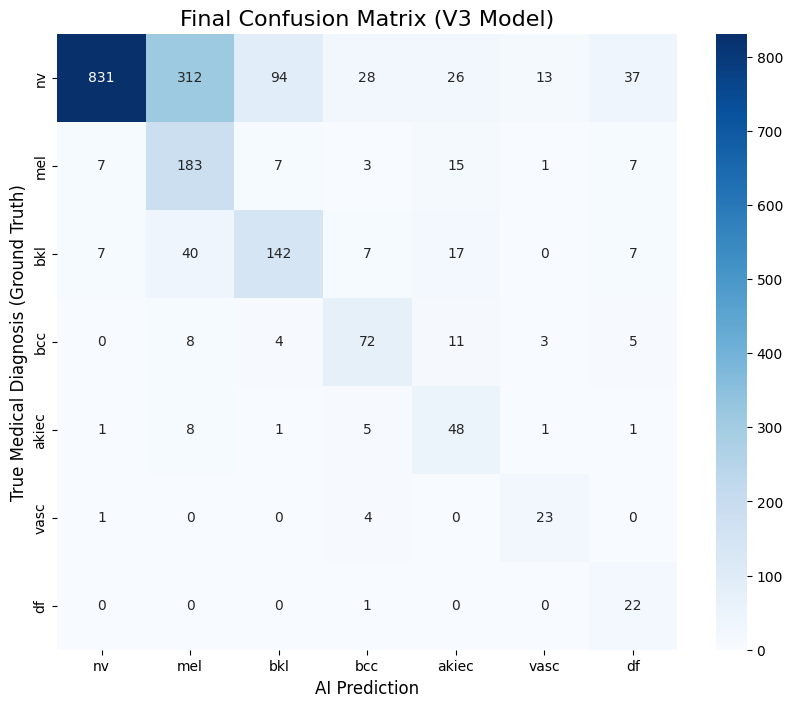


=== CRITICAL MEDICAL REPORT: MELANOMA (mel) ===
Total actual Melanomas in Validation Set: 223
✅ True Positives (Successfully detected): 183
❌ FALSE NEGATIVES (Missed cancers): 40 (17.9%)
⚠️ False Positives (False alarms): 368

Melanoma Precision: 0.33 (Target: Reduce false alarms)
Melanoma Recall: 0.82 (Target: Keep this as high as possible)


In [14]:
# ==========================================
# 4. Final Evaluation of the V3 Model (Focal Loss + Sampler)
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

print("Generating Final Evaluation Report...")

# 1. Define the class names in the correct order based on our label_map
target_names = ['nv', 'mel', 'bkl', 'bcc', 'akiec', 'vasc', 'df']

# 2. Print the Classification Report
# This will show Precision, Recall, and F1-Score for ALL classes
print("\n=== V3 MODEL METRICS (FOCAL LOSS + BALANCED SAMPLER) ===")
print(classification_report(val_labels_final, val_preds_final, target_names=target_names, zero_division=0))

# 3. Compute and plot the Confusion Matrix
cm_final = confusion_matrix(val_labels_final, val_preds_final)

plt.figure(figsize=(10, 8))
sns.heatmap(cm_final, annot=True, fmt='d', cmap='Blues', 
            xticklabels=target_names, yticklabels=target_names)
plt.title('Final Confusion Matrix (V3 Model)', fontsize=16)
plt.ylabel('True Medical Diagnosis (Ground Truth)', fontsize=12)
plt.xlabel('AI Prediction', fontsize=12)
plt.show()

# 4. Deep Dive into the Melanoma (mel) class
mel_index = 1 # 'mel' is at index 1
tp_mel = cm_final[mel_index, mel_index]
fn_mel = sum(cm_final[mel_index, :]) - tp_mel
fp_mel = sum(cm_final[:, mel_index]) - tp_mel
total_mel = tp_mel + fn_mel

print("\n=== CRITICAL MEDICAL REPORT: MELANOMA (mel) ===")
print(f"Total actual Melanomas in Validation Set: {total_mel}")
print(f"✅ True Positives (Successfully detected): {tp_mel}")
print(f"❌ FALSE NEGATIVES (Missed cancers): {fn_mel} ({(fn_mel/total_mel)*100:.1f}%)")
print(f"⚠️ False Positives (False alarms): {fp_mel}")

# Calculate specific metrics for Melanoma
precision_mel = tp_mel / (tp_mel + fp_mel) if (tp_mel + fp_mel) > 0 else 0
recall_mel = tp_mel / total_mel if total_mel > 0 else 0

print(f"\nMelanoma Precision: {precision_mel:.2f} (Target: Reduce false alarms)")
print(f"Melanoma Recall: {recall_mel:.2f} (Target: Keep this as high as possible)")